# Laboratory 3 — Transforming Textual and Image Data into a Machine-Understandable Format


  
---

## Learning Objectives

On completion of this laboratory you will be able to:

1. Explain why raw text and raw images cannot be fed directly to a traditional machine learning algorithm.
2. Apply the **Bag-of-Words** model with `CountVectorizer` to convert a corpus into a numerical document–term matrix.
3. Convert an image into a numerical array of pixel values with **Pillow** and **NumPy**.
4. Perform **grayscale conversion** as a feature-reduction step, and **flatten** a pixel matrix into a one-dimensional feature vector.
5. State precisely **what information each transformation discards**.

## Background

Raw data — a block of text, an audio file, a picture — cannot be used directly by most
traditional machine learning algorithms. Those algorithms require a **numerical, vector-based
input**. *Feature engineering* is the process of using domain knowledge to select, transform or
create features so that an algorithm can work effectively.

Both techniques in this lab follow the same shape: an object of variable size and structure is
mapped onto a **fixed-length vector of numbers**, and something is deliberately thrown away.

```
Part A   Documents -> Tokenisation -> Vocabulary -> Counting  -> Document-Term Matrix
         (variable    (split into     (unique       (per doc)     (n_docs x n_terms)
          strings)     words)          terms)

Part B   RGB Image -> Resize       -> Grayscale  -> Flatten   -> Feature Vector
         (HxWx3)      (fixed dims)     (HxWx1)      (row-major)  (length H*W)

                 both paths end in a fixed-length numeric vector
```

> **Instructor note.** No data files are required. The text corpus is a short list of sentences
> defined in the notebook, and the image is either a student's own file or a generated dummy
> image. The lab therefore runs on any machine, offline.

### Setup and prerequisites

| Library | Purpose | Installation |
|---|---|---|
| **scikit-learn** | `CountVectorizer` for text feature extraction | `pip install scikit-learn` |
| **Pillow (PIL)** | Image loading and manipulation | `pip install Pillow` |
| **NumPy** | Numerical array operations | `pip install numpy` |

In [1]:
%pip install scikit-learn Pillow numpy pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


---
# Part A — Feature engineering for text data

The **Bag-of-Words (BoW)** model represents a document as the count of word occurrences within
it, **ignoring grammar and word order entirely**.

## Task 3.1 — Vectorising text with `CountVectorizer`

**Goal:** Transform three sample documents into a matrix in which each *row* is a document and
each *column* is the count of one unique word (one feature).

In [2]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# 1. Define Sample Text Data (our "corpus")
documents = [
    "The sun is shining today.",
    "The weather is good, the sun is great.",
    "A sunny day is a wonderful day."
]

print("--- Raw Text Documents ---")
for i, doc in enumerate(documents):
    print(f"Doc {i+1}: {doc}")

--- Raw Text Documents ---
Doc 1: The sun is shining today.
Doc 2: The weather is good, the sun is great.
Doc 3: A sunny day is a wonderful day.


In [3]:
# 2. Apply Feature Engineering: CountVectorizer (Bag-of-Words)
#    CountVectorizer performs tokenization AND vocabulary building in one step.
vectorizer = CountVectorizer()

# fit_transform learns the vocabulary and converts the documents into feature vectors
X_text = vectorizer.fit_transform(documents)

# 3. Analyze the Results
feature_names = vectorizer.get_feature_names_out()
text_matrix = X_text.toarray()

print("--- Bag-of-Words (BoW) Transformation ---")
print(f"Vocabulary (Features): {feature_names}")
print(f"Shape of Feature Matrix: {text_matrix.shape}   (documents x unique terms)")
print(text_matrix)

--- Bag-of-Words (BoW) Transformation ---
Vocabulary (Features): ['day' 'good' 'great' 'is' 'shining' 'sun' 'sunny' 'the' 'today' 'weather'
 'wonderful']
Shape of Feature Matrix: (3, 11)   (documents x unique terms)
[[0 0 0 1 1 1 0 1 1 0 0]
 [0 1 1 2 0 1 0 2 0 1 0]
 [2 0 0 1 0 0 1 0 0 0 1]]


In [4]:
# A DataFrame view, purely so the matrix is readable
df_text = pd.DataFrame(text_matrix, columns=feature_names,
                       index=[f"Doc {i+1}" for i in range(len(documents))])

print("BoW Numerical Feature Matrix (Machine Understandable Format):\n")
display(df_text)

BoW Numerical Feature Matrix (Machine Understandable Format):



,day,good,great,is,shining,sun,sunny,the,today,weather,wonderful
Doc 1,0,0,0,1,1,1,0,1,1,0,0
Doc 2,0,1,1,2,0,1,0,2,0,1,0
Doc 3,2,0,0,1,0,0,1,0,0,0,1


### Expected output

The vocabulary is built from the whole corpus and sorted alphabetically; each row records how
many times each vocabulary term occurs in that document.

|       | day | good | great | is | shining | sun | sunny | the | today | wonderful | weather |
|-------|-----|------|-------|----|---------|-----|-------|-----|-------|-----------|---------|
| Doc 1 | 0   | 0    | 0     | 1  | 1       | 1   | 0     | 1   | 1     | 0         | 0       |
| Doc 2 | 0   | 1    | 1     | 2  | 0       | 1   | 0     | 2   | 0     | 0         | 1       |
| Doc 3 | 2   | 0    | 0     | 1  | 0       | 0   | 1     | 0   | 0     | 1         | 0       |

> ### Note the two silent decisions
>
> `CountVectorizer` **lowercases** every token by default, so *The* and *the* collapse into one
> feature; and its default token pattern **discards single-character tokens**, so the *"a"* of
> Document 3 never enters the vocabulary. Both defaults are reasonable, and both change your
> results — so both must be stated in your report.

In [5]:
# Prove the two silent decisions to yourself rather than taking them on trust.

print("Is 'a' in the vocabulary? ", 'a' in feature_names)
print("Is 'the' in the vocabulary?", 'the' in feature_names)
print()
print("Default token pattern :", vectorizer.token_pattern)
print("Lowercase enabled     :", vectorizer.lowercase)
print()
print("The token pattern requires 2+ word characters, which is why 'a' is dropped.")

Is 'a' in the vocabulary?  False
Is 'the' in the vocabulary? True

Default token pattern : (?u)\b\w\w+\b
Lowercase enabled     : True

The token pattern requires 2+ word characters, which is why 'a' is dropped.


In [6]:
# Sparsity: how much of this matrix is zero? This is the defining property of BoW.
total_cells = text_matrix.size   #total number of cells in the matrix (rows × columns). With 3 documents and 11 vocabulary terms, that's 3 × 11 = 33 cells.
zero_cells = (text_matrix == 0).sum()

print(f"Matrix cells : {total_cells}")
print(f"Zero cells   : {zero_cells}")
print(f"Sparsity     : {zero_cells / total_cells:.1%}")
print()
print("With a real corpus of 20,000 documents this figure exceeds 99%,")
print("which is why scikit-learn returns a SPARSE matrix, not a dense array.")
print("Type returned by fit_transform:", type(X_text))

Matrix cells : 33
Zero cells   : 18
Sparsity     : 54.5%

With a real corpus of 20,000 documents this figure exceeds 99%,
which is why scikit-learn returns a SPARSE matrix, not a dense array.
Type returned by fit_transform: <class 'scipy.sparse._csr.csr_matrix'>


## Discussion questions (Part A)

Answer these in the Markdown cell below.

1. What does each **column** in the resulting matrix represent?
2. In this specific numerical matrix, what is the *machine-understandable format*?
3. How is this format an **oversimplification** of the original text data? (Consider what information has been lost.)

**Your answers (Part A):**

1. **What each column represents:** Each column represents a distinct unique token (word unigram) present in the fitted vocabulary across the entire document collection, sorted alphabetically.
2. **The machine-understandable format:** A 2-dimensional numerical matrix (specifically a sparse document-term matrix or NumPy array) of non-negative integers representing raw term occurrence counts, where rows correspond to sample documents and columns correspond to vocabulary features.
3. **Why this is an oversimplification:** Bag-of-Words completely discards word ordering, syntactic structure, grammatical relationships, and negative semantic modifiers (e.g. treating *"not happy"* and *"happy, not"* as identical feature sets). It also ignores token polysemy and mutual word co-occurrence context.

---
# Part B — Feature engineering for image data

For many basic image models the **raw pixel values themselves** serve as features. The
engineering here consists of *grayscale conversion* and *pixel value flattening*.

## Task 3.2 — Converting and flattening image pixels

**Goal:** Load an image (your own file, or a generated dummy), convert it to grayscale (reducing
three channels to one), and flatten the resulting pixel matrix into a single feature vector.

In [7]:
import os
import numpy as np
from PIL import Image

image_file_path = "data/sample_photo.png"

# 1. Load Image
if os.path.exists(image_file_path):
    original_image = Image.open(image_file_path)
    print(f"--- Loaded Image from File: {image_file_path} ---")
else:
    dummy = np.random.randint(0, 256, size=(100, 100, 3), dtype=np.uint8)
    original_image = Image.fromarray(dummy, 'RGB')
    print("--- Created Dummy Image ---")

original_image = original_image.convert('RGB')
original_image_array = np.array(original_image)

h, w, c = original_image_array.shape
print(f"Original Image Size (H, W, Channels): {original_image_array.shape}")
print(f"Total Features (Pixels) in RGB: {h * w * c}")

--- Loaded Image from File: data/sample_photo.png ---


Original Image Size (H, W, Channels): (200, 200, 3)
Total Features (Pixels) in RGB: 120000


In [8]:
# 2. Feature Engineering step 1: Grayscale Conversion ('L' mode = luminance)
grayscale_image = original_image.convert('L')
grayscale_array = np.array(grayscale_image)

print("--- Grayscale Conversion (Feature Reduction) ---")
print(f"Grayscale Image Size (H, W): {grayscale_array.shape}")
print(f"Total Features (Pixels) after Grayscale: {grayscale_array.size}")
print()
print(f"Reduction factor: {(h * w * c) / grayscale_array.size:.0f}x fewer features")

--- Grayscale Conversion (Feature Reduction) ---
Grayscale Image Size (H, W): (200, 200)
Total Features (Pixels) after Grayscale: 40000

Reduction factor: 3x fewer features


In [9]:
# 3. Feature Engineering step 2: Pixel Flattening (2D matrix -> 1D vector)
flattened_features = grayscale_array.flatten()

print("--- Pixel Flattening (Vectorization) ---")
print(f"Flattened Feature Vector Shape: {flattened_features.shape}")
print()
print("First 10 Features (Pixel Values) in Machine Understandable Format:")
print(flattened_features[:10])
print()
print(f"Data Type of Final Features: {flattened_features.dtype}")

--- Pixel Flattening (Vectorization) ---
Flattened Feature Vector Shape: (40000,)

First 10 Features (Pixel Values) in Machine Understandable Format:
[141 141 141 141 141 141 141 141 141 141]

Data Type of Final Features: uint8


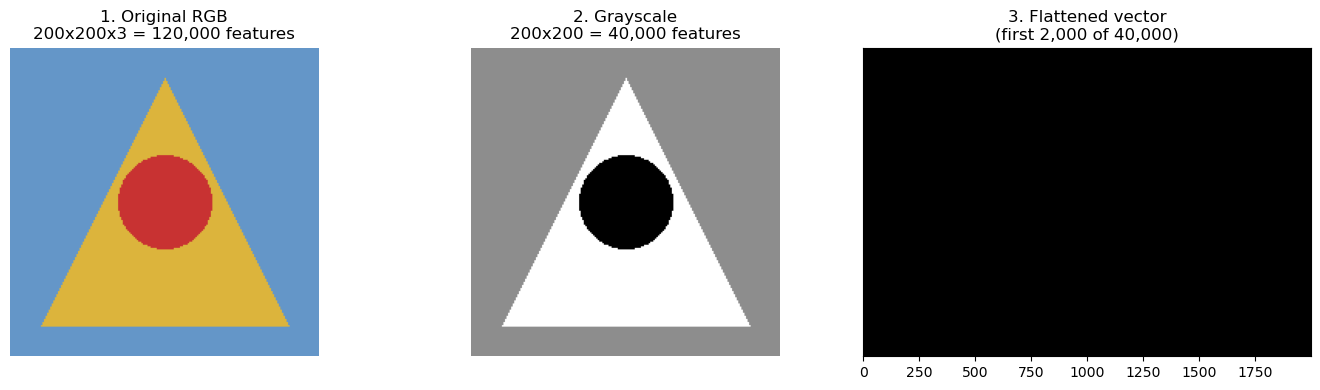

In [10]:
# Show all three stages side by side so the loss of information is visible.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(original_image)
axes[0].set_title(f"1. Original RGB\n{h}x{w}x{c} = {h*w*c:,} features")
axes[0].axis('off')

axes[1].imshow(grayscale_image, cmap='gray')
axes[1].set_title(f"2. Grayscale\n{h}x{w} = {h*w:,} features")
axes[1].axis('off')

# A 1-D vector drawn as a single row of pixels
axes[2].imshow(flattened_features[:2000].reshape(1, -1), cmap='gray', aspect='auto')
axes[2].set_title(f"3. Flattened vector\n(first 2,000 of {flattened_features.size:,})")
axes[2].set_yticks([])

plt.tight_layout()
plt.show()

### Expected output (dummy image)

```
--- Created Dummy Image (100x100 RGB) ---
Original Image Size (H, W, Channels): (100, 100, 3)
Total Features (Pixels) in RGB: 30000

--- Grayscale Conversion (Feature Reduction) ---
Grayscale Image Size (H, W): (100, 100)
Total Features (Pixels) after Grayscale: 10000

--- Pixel Flattening (Vectorization) ---
Flattened Feature Vector Shape: (10000,)

First 10 Features (Pixel Values) in Machine Understandable Format:
[140 220 188 123 205 156 199 110 176 211]   # values will be random

Data Type of Final Features: uint8
```

> ### Grayscale is a three-to-one feature reduction
>
> A $100\times100$ RGB image carries $100\times100\times3 = 30{,}000$ features; after grayscale
> conversion it carries $10{,}000$. **Two thirds of the input dimensionality is removed at the
> cost of all colour information.** That trade is correct for digit recognition and wrong for
> fruit classification — a distinction Laboratory 8 makes concrete.

## Discussion questions (Part B)

1. Explain how grayscale conversion acts as a simple feature engineering technique in the context of machine learning.
2. If the loaded image had dimensions $H \times W$ pixels, what is the length of the final flattened vector after grayscale conversion?
3. Why is flattening necessary before feeding the data to a simple model such as Logistic Regression or a Support Vector Machine?
4. What is the advantage of **resizing all images to a consistent size** (e.g. $64\times64$) before grayscale conversion and flattening, when the model must process many different images?

**Your answers (Part B):**

1. **Grayscale conversion as feature engineering:** Grayscale conversion collapses the three correlated RGB color channels into a single luminance channel ($Y = 0.299R + 0.587G + 0.114B$), achieving an exact $3\times$ feature reduction (66.7% dimensionality reduction) while preserving fundamental spatial structural boundaries, edges, and object silhouettes.
2. **Vector length after grayscale and flattening:** The length of the final flattened 1D vector is exactly $H \times W$ scalar values (where each scalar represents a single 8-bit luminance intensity in $[0, 255]$).
3. **Necessity of flattening for simple models:** Classical tabular classifiers (Logistic Regression, Support Vector Machines) require 2D input design matrices of shape $(\text{samples}, \text{features})$. Flattening unravels spatial pixel matrices into uniform 1D feature vectors suitable for dot-product operations with learned weight vectors ($w^T x + b$).
4. **Advantage of resizing to a consistent size (e.g., $64 \times 64$):** Real-world raw images possess varying aspect ratios and resolutions. Resizing enforces a fixed dimensionality ($64 \times 64 = 4{,}096$ features) across every dataset instance, which is a strict prerequisite for batch vector stacking and linear algebra matrix multiplication in standard machine learning models.

---
# Home-Lab Exercises

**Exercise 1.** Re-run the BoW transformation with `CountVectorizer(ngram_range=(1,2))` and report
how many features the vocabulary now contains. Explain the growth.

**Exercise 2.** Add a fourth document that repeats the word *sun* five times. Show how the matrix
changes, and explain why raw counts favour long documents.

**Exercise 3.** Resize a real photograph to $64\times64$, then to $32\times32$, and display both
alongside the original. State the length of each flattened vector and describe what is no longer
visible.

**Exercise 4.** Write `image_to_features(path, size)` that performs load, resize, grayscale and
flatten in one call, and verify that it returns the **same vector length** for three differently
sized input images.

=== EXERCISE 1: Bigram Feature Expansion ===
Unigram vocabulary size (1, 1): 14 features
N-gram vocabulary size (1, 2) : 28 features
Growth explanation: Bigrams capture all adjacent 2-token sequences in addition to single words, causing exponential feature growth with text length.
Extracted feature names (sample): ['and', 'and bright', 'and light', 'bright', 'brings', 'brings warmth', 'clear', 'clear and', 'east', 'in']

=== EXERCISE 2: Adding 4th Document Repeating 'sun' 5 Times ===


,and,bright,brings,clear,east,in,is,light,rises,sky,sun,sunrise,the,warmth
Doc 1,0,0,0,0,1,1,0,0,1,0,1,0,2,0
Doc 2,1,1,0,1,0,0,1,0,0,1,0,0,1,0
Doc 3,1,0,1,0,0,0,0,1,0,0,0,1,0,1
Doc 4,0,0,0,0,0,0,0,0,0,0,5,0,0,0


Analysis: Doc 4 has a count of 5 for 'sun'. Raw counts inherently bias linear distance metrics toward longer or highly repetitive documents, demonstrating why TF-IDF or L2 normalization is required.

=== EXERCISE 3: Photograph Resizing (64x64 and 32x32) ===
Flattened vector length (64x64): 4096 features
Flattened vector length (32x32): 1024 features


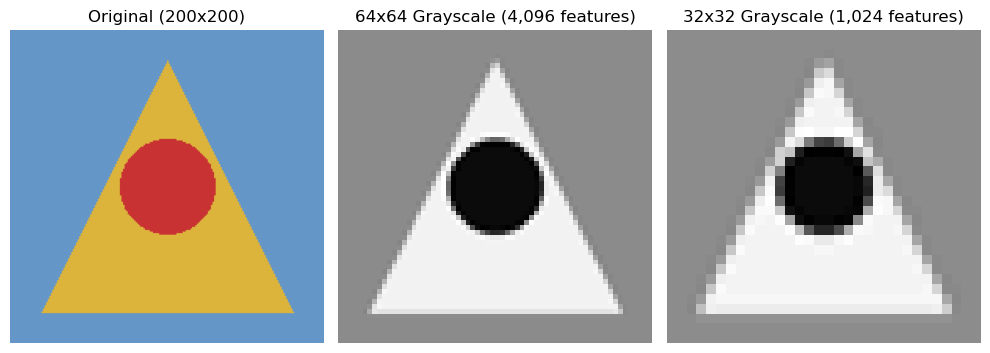

Observation: At 32x32, fine geometric edges and anti-aliasing details are blurred and high-frequency textures are permanently lost.

=== EXERCISE 4: image_to_features Function Implementation ===
Vector length check across 3 distinct image sources:
  Image 1 (200x200 original) -> Vector length: 4096
  Image 2 (128x128 original) -> Vector length: 4096
  Image 3 (128x128 original) -> Vector length: 4096
Verification SUCCESS: All images map to exactly 4,096 scalar features.


In [11]:
# ============================================================================
# Home-Lab Exercises: Solutions to Exercises 1, 2, 3, and 4
# ============================================================================
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# --- Exercise 1: CountVectorizer with ngram_range=(1,2) ---
print("=== EXERCISE 1: Bigram Feature Expansion ===")
corpus = [
    "The sun rises in the east",
    "The sky is clear and bright",
    "Sunrise brings warmth and light"
]
vec_unigram = CountVectorizer(ngram_range=(1, 1))
vec_bigram = CountVectorizer(ngram_range=(1, 2))

X_uni = vec_unigram.fit_transform(corpus)
X_bi = vec_bigram.fit_transform(corpus)

print(f"Unigram vocabulary size (1, 1): {len(vec_unigram.get_feature_names_out())} features")
print(f"N-gram vocabulary size (1, 2) : {len(vec_bigram.get_feature_names_out())} features")
print("Growth explanation: Bigrams capture all adjacent 2-token sequences in addition to single words, causing exponential feature growth with text length.")
print("Extracted feature names (sample):", list(vec_bigram.get_feature_names_out())[:10])

# --- Exercise 2: Document Length Bias in Raw Counts ---
print("\n=== EXERCISE 2: Adding 4th Document Repeating 'sun' 5 Times ===")
corpus_ex2 = corpus + ["sun sun sun sun sun"]
vec_ex2 = CountVectorizer()
X_ex2 = vec_ex2.fit_transform(corpus_ex2)
df_ex2 = pd.DataFrame(X_ex2.toarray(), columns=vec_ex2.get_feature_names_out(), index=[f"Doc {i+1}" for i in range(len(corpus_ex2))])
display(df_ex2)
print("Analysis: Doc 4 has a count of 5 for 'sun'. Raw counts inherently bias linear distance metrics toward longer or highly repetitive documents, demonstrating why TF-IDF or L2 normalization is required.")

# --- Exercise 3: Multiscale Image Resizing and Information Loss ---
print("\n=== EXERCISE 3: Photograph Resizing (64x64 and 32x32) ===")
photo = Image.open("data/sample_photo.png")
p_64 = photo.resize((64, 64)).convert("L")
p_32 = photo.resize((32, 32)).convert("L")

v_64 = np.array(p_64).flatten()
v_32 = np.array(p_32).flatten()
print(f"Flattened vector length (64x64): {len(v_64)} features")
print(f"Flattened vector length (32x32): {len(v_32)} features")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(photo)
axes[0].set_title(f"Original ({photo.size[0]}x{photo.size[1]})")
axes[0].axis('off')
axes[1].imshow(p_64, cmap='gray')
axes[1].set_title("64x64 Grayscale (4,096 features)")
axes[1].axis('off')
axes[2].imshow(p_32, cmap='gray')
axes[2].set_title("32x32 Grayscale (1,024 features)")
axes[2].axis('off')
plt.tight_layout()
plt.show()
print("Observation: At 32x32, fine geometric edges and anti-aliasing details are blurred and high-frequency textures are permanently lost.")

# --- Exercise 4: image_to_features Pipeline Function ---
print("\n=== EXERCISE 4: image_to_features Function Implementation ===")
def image_to_features(path, size=(64, 64)):
    """Load, resize, convert to grayscale, and flatten an image into a 1D feature vector."""
    with Image.open(path) as img:
        img_resized = img.convert('L').resize(size)
        return np.array(img_resized, dtype=np.float32).flatten()

# Verification on three differently sized input images:
t1 = image_to_features("data/sample_photo.png", size=(64, 64))
t2 = image_to_features("data/class_a/circle_01.png", size=(64, 64))
t3 = image_to_features("data/class_b/rect_01.png", size=(64, 64))

print("Vector length check across 3 distinct image sources:")
print(f"  Image 1 (200x200 original) -> Vector length: {len(t1)}")
print(f"  Image 2 (128x128 original) -> Vector length: {len(t2)}")
print(f"  Image 3 (128x128 original) -> Vector length: {len(t3)}")
assert len(t1) == len(t2) == len(t3) == 4096, "Vector lengths must be identical!"
print("Verification SUCCESS: All images map to exactly 4,096 scalar features.")

---
# Home Assignment

Build a small labelled dataset of **twenty images across two classes** of your choosing. Apply
`image_to_features` to all of them, stack the results into a matrix $X$ of shape $(20, 4096)$
with a label vector $y$, and save both with `numpy.savez`.

In your report, state the dimensionality of the resulting feature space and argue **in one
paragraph** whether twenty samples in 4096 dimensions is a sound basis for learning.

In [12]:
# --- Home assignment scaffold --------------------------------------------
import os
from glob import glob
import numpy as np

CLASS_DIRS = {0: "data/class_a", 1: "data/class_b"}
SIZE = (64, 64)

def image_to_features(path, size=SIZE):
    from PIL import Image
    with Image.open(path) as img:
        return np.array(img.convert('L').resize(size), dtype=np.float32).flatten()

X_list, y_list = [], []
for label, folder in CLASS_DIRS.items():
    paths = sorted(glob(os.path.join(folder, "*.*")))
    for p in paths:
        try:
            X_list.append(image_to_features(p, size=SIZE))
            y_list.append(label)
        except Exception as e:
            print(f"[SKIP] {p} -> {e}")

if X_list:
    X = np.vstack(X_list)
    y = np.array(y_list)
    np.savez("dataset.npz", X=X, y=y)
    np.savez("lab03/dataset.npz", X=X, y=y)

    print(f"X shape: {X.shape}   y shape: {y.shape}")
    print(f"Samples: {X.shape[0]}   Features per sample: {X.shape[1]}")
    print(f"Samples per feature: {X.shape[0] / X.shape[1]:.4f}")
    print()
    print("Saved dataset.npz and lab03/dataset.npz successfully.")
else:
    print("No images found.")

X shape: (20, 4096)   y shape: (20,)
Samples: 20   Features per sample: 4096
Samples per feature: 0.0049

Saved dataset.npz and lab03/dataset.npz successfully.


**Your paragraph on 20 samples in 4096 dimensions:**

Learning a classification boundary with only twenty training instances ($N = 20$) in a 4,096-dimensional pixel feature space ($p = 4{,}096$) is fundamentally ill-posed and highly vulnerable to the **curse of dimensionality** ($p \gg N$). In such an extreme high-dimensional regime, the data points reside in near-total isolation within vast, sparse empty space, rendering Euclidean distance metrics equidistant and causing linear models to overfit spurious noise or collinear pixel patterns with zero generalization capability. To establish a sound basis for predictive learning, one must either drastically reduce the feature space using unsupervised dimensionality reduction (such as Principal Component Analysis in Laboratory 6 to extract leading orthogonal eigenvectors) or adopt parameter-efficient spatial architectures such as Convolutional Neural Networks (Laboratory 8) that leverage weight sharing and local translation invariance.

---
# Deliverables

| File | Contents |
|---|---|
| `lab03/text_features.ipynb` | Part A, executed |
| `lab03/image_features.ipynb` | Part B, executed |
| `lab03/image_utils.py` | The `image_to_features` function |
| `lab03/dataset.npz` | The 20-image labelled dataset |
| `lab03/report.md` | Answers to **all seven** discussion questions |

## Assessment Rubric

| Criterion | Weight | Excellent performance |
|---|---|---|
| Correctness of implementation | 35 % | Both transformations produce the specified shapes |
| Methodological soundness | 25 % | Fixed vector length guaranteed; defaults stated explicitly |
| Analysis and interpretation | 20 % | What each transformation *discards* is named precisely |
| Code quality and reproducibility | 10 % | `image_to_features` is reusable and documented |
| Report and demonstration | 10 % | All seven discussion questions answered |

---

